<a href="https://colab.research.google.com/github/Chaki34/SaiKet_Systems_Data_Science_Internship/blob/main/Task%204%20%E2%80%93%20Churn%20Prediction%20Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 4 – Churn Prediction Model

## SaiKet Systems – Data Science Internship

### Project Objective
The objective of this task is to develop machine learning models
to predict customer churn using the Telco Customer Churn dataset.

### Algorithms
1. Logistic Regression
2. Decision Tree Classifier

### Activities
- Data preprocessing
- Train-test splitting
- Model training
- Model performance evaluation
- Feature selection
- Hyperparameter tuning

### Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-score

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_selection import SelectFromModel

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from sklearn.base import clone
import joblib
import os
import warnings

warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Saving Telco_Customer_Churn_Dataset  (3) (1).csv to Telco_Customer_Churn_Dataset  (3) (1).csv
Dataset loaded successfully!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nChurn Distribution:")
print(df["Churn"].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

In [4]:
# Remove duplicate records
df = df.drop_duplicates().copy()

# Remove unnecessary spaces from column values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Convert TotalCharges into numeric format
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(
        df["TotalCharges"], errors="coerce"
    )

# Remove rows with missing target values
df = df.dropna(subset=["Churn"])

# Convert churn into numerical values
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Remove rows where target conversion failed
df = df.dropna(subset=["Churn"])

df["Churn"] = df["Churn"].astype(int)

print("Data cleaning completed!")
print("Updated Dataset Shape:", df.shape)

display(df.head())

Data cleaning completed!
Updated Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [5]:
# Separate target variable
y = df["Churn"]

# Remove target and customer ID from input features
X = df.drop(
    columns=["Churn", "customerID"],
    errors="ignore"
)

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nTarget Distribution:")
print(y.value_counts())

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Target Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Data Shape: (5634, 19)
Testing Data Shape: (1409, 19)

Training Target Distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing Target Distribution:
Churn
0    1035
1     374
Name: count, dtype: int64


In [7]:
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [8]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    )
}

print("Machine learning models created:")
for name in models:
    print("-", name)

Machine learning models created:
- Logistic Regression
- Decision Tree


In [9]:
baseline_results = []
baseline_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", clone(model))
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(
        y_test, predictions, zero_division=0
    )
    recall = recall_score(
        y_test, predictions, zero_division=0
    )
    f1 = f1_score(
        y_test, predictions, zero_division=0
    )

    baseline_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    baseline_models[name] = pipeline

    print("\n", "=" * 45)
    print(name)
    print("=" * 45)

    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-Score:", round(f1, 4))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        predictions,
        target_names=["No Churn", "Churn"],
        zero_division=0
    ))

baseline_df = pd.DataFrame(baseline_results)

display(baseline_df)


Logistic Regression
Accuracy: 0.7381
Precision: 0.5043
Recall: 0.7834
F1-Score: 0.6136

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409


Decision Tree
Accuracy: 0.7282
Precision: 0.4878
Recall: 0.4813
F1-Score: 0.4845

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.81      0.82      0.82      1035
       Churn       0.49      0.48      0.48       374

    accuracy                           0.73      1409
   macro avg       0.65      0.65      0.65      1409
weighted avg       0.73      0.73      0.73      1409



,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.738112,0.504303,0.783422,0.613613
1,Decision Tree,0.728176,0.487805,0.481283,0.484522


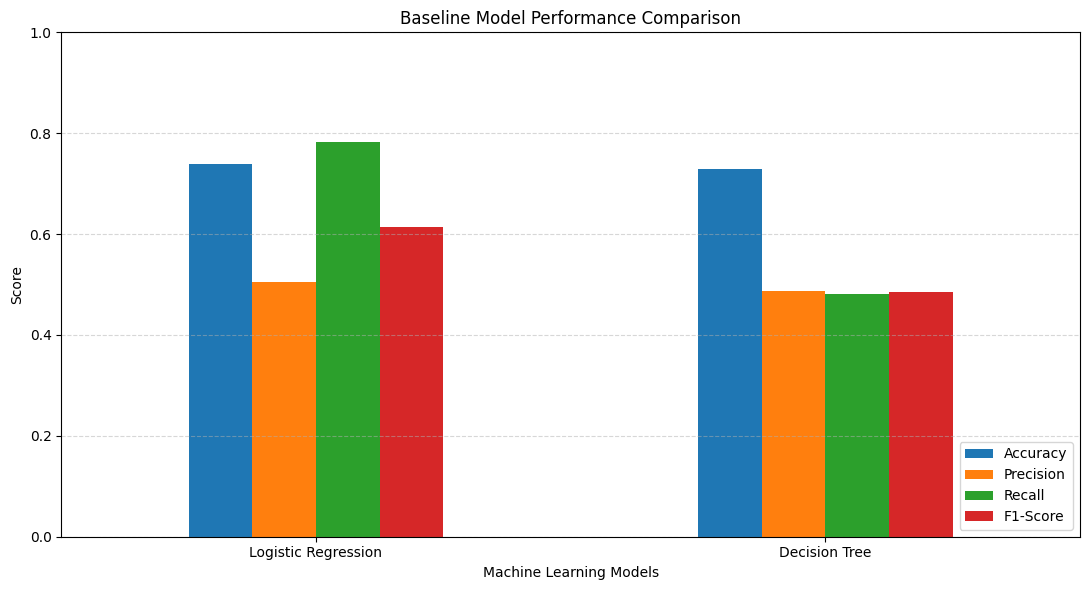

In [10]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

baseline_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Baseline Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [11]:
feature_selector = SelectFromModel(
    estimator=DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),
    threshold="median"
)

print("Feature selection method initialized!")

Feature selection method initialized!


In [12]:
logistic_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("feature_selection", clone(feature_selector)),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_parameters = {
    "model__C": [0.1, 1, 10],
    "model__solver": ["liblinear"]
}

logistic_grid = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_parameters,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

logistic_grid.fit(X_train, y_train)

print("Best Logistic Regression Parameters:")
print(logistic_grid.best_params_)

print("Best Cross-Validation F1-Score:")
print(round(logistic_grid.best_score_, 4))

Fitting 5 folds for each of 3 candidates, totalling 15 fits
Best Logistic Regression Parameters:
{'model__C': 1, 'model__solver': 'liblinear'}
Best Cross-Validation F1-Score:
0.6332


In [14]:
tree_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("feature_selection", clone(feature_selector)),
    ("model", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

tree_parameters = {
    "model__max_depth": [3, 5, 8, None],
    "model__min_samples_split": [2, 10, 20],
    "model__min_samples_leaf": [1, 5, 10],
    "model__criterion": ["gini", "entropy"]
}

tree_grid = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=tree_parameters,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

tree_grid.fit(X_train, y_train)

print("Best Decision Tree Parameters:")
print(tree_grid.best_params_)

print("Best Cross-Validation F1-Score:")
print(round(tree_grid.best_score_, 4))

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best Decision Tree Parameters:
{'model__criterion': 'gini', 'model__max_depth': 3, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}
Best Cross-Validation F1-Score:
0.6204


In [16]:
tuned_models = {
    "Tuned Logistic Regression": logistic_grid.best_estimator_,
    "Tuned Decision Tree": tree_grid.best_estimator_
}

tuned_results = []

for name, model in tuned_models.items():

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(
        y_test, predictions, zero_division=0
    )
    recall = recall_score(
        y_test, predictions, zero_division=0
    )
    f1 = f1_score(
        y_test, predictions, zero_division=0
    )

    tuned_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    print("\n", "=" * 45)
    print(name)
    print("=" * 45)

    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-Score:", round(f1, 4))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        predictions,
        target_names=["No Churn", "Churn"],
        zero_division=0
    ))

tuned_df = pd.DataFrame(tuned_results)

display(tuned_df)


Tuned Logistic Regression
Accuracy: 0.7381
Precision: 0.5043
Recall: 0.7834
F1-Score: 0.6136

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409


Tuned Decision Tree
Accuracy: 0.7459
Precision: 0.514
Recall: 0.7834
F1-Score: 0.6208

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.90      0.73      0.81      1035
       Churn       0.51      0.78      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.75      0.76      1409



,Model,Accuracy,Precision,Recall,F1-Score
0,Tuned Logistic Regression,0.738112,0.504303,0.783422,0.613613
1,Tuned Decision Tree,0.745919,0.514035,0.783422,0.620763


Complete Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1-Score
0,Tuned Decision Tree,0.745919,0.514035,0.783422,0.620763
1,Logistic Regression,0.738112,0.504303,0.783422,0.613613
2,Tuned Logistic Regression,0.738112,0.504303,0.783422,0.613613
3,Decision Tree,0.728176,0.487805,0.481283,0.484522


<Figure size 1200x600 with 0 Axes>

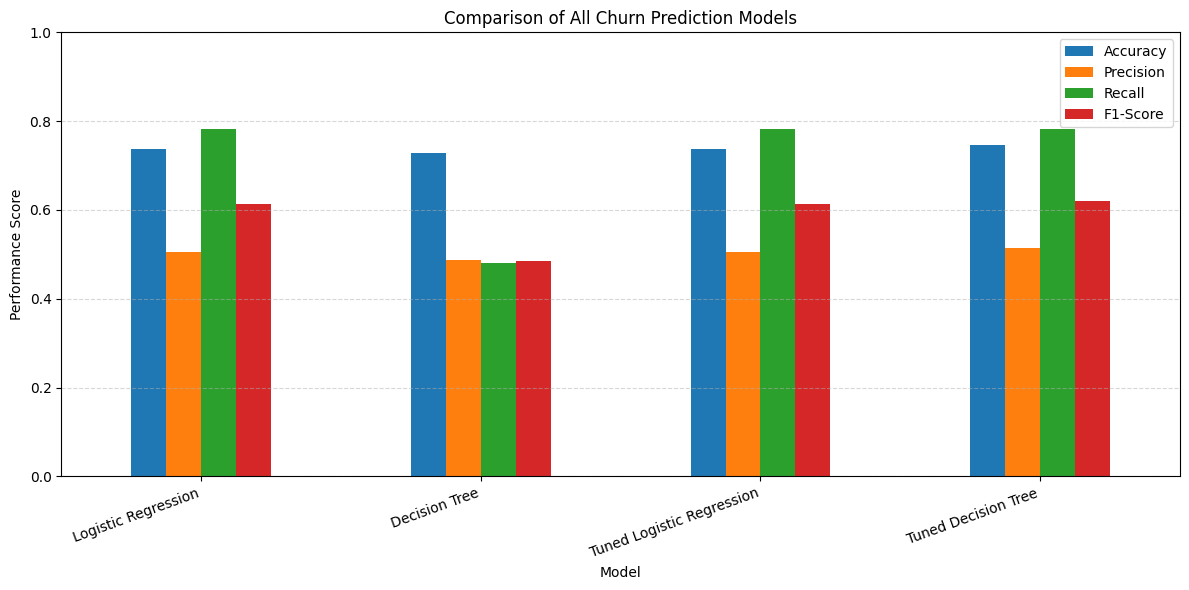

In [17]:
all_results = pd.concat(
    [baseline_df, tuned_df],
    ignore_index=True
)

print("Complete Model Performance Comparison:")

display(
    all_results.sort_values(
        by="F1-Score",
        ascending=False
    ).reset_index(drop=True)
)

plt.figure(figsize=(12, 6))

all_results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Comparison of All Churn Prediction Models")
plt.ylabel("Performance Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [18]:
best_model_name = all_results.loc[
    all_results["F1-Score"].idxmax(),
    "Model"
]

if best_model_name == "Tuned Logistic Regression":
    best_model = logistic_grid.best_estimator_

elif best_model_name == "Tuned Decision Tree":
    best_model = tree_grid.best_estimator_

elif best_model_name == "Logistic Regression":
    best_model = baseline_models["Logistic Regression"]

else:
    best_model = baseline_models["Decision Tree"]

print("Best Model:", best_model_name)

best_predictions = best_model.predict(X_test)

print("\nFinal Model Performance:")
print(classification_report(
    y_test,
    best_predictions,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

Best Model: Tuned Decision Tree

Final Model Performance:
              precision    recall  f1-score   support

    No Churn       0.90      0.73      0.81      1035
       Churn       0.51      0.78      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.75      0.76      1409



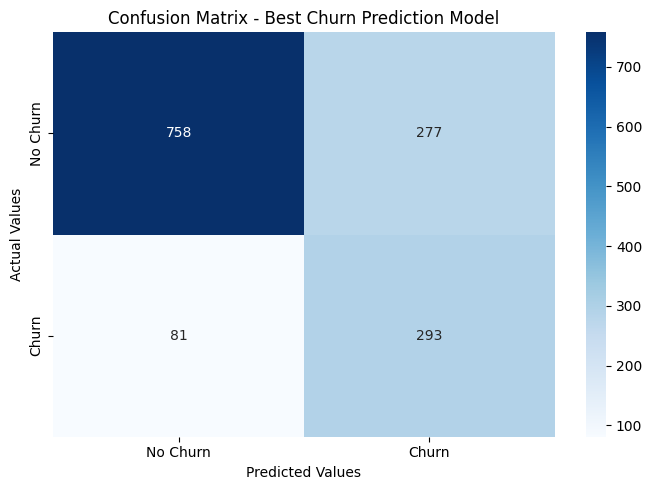

In [19]:
cm = confusion_matrix(y_test, best_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Confusion Matrix - Best Churn Prediction Model")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.tight_layout()
plt.show()

In [20]:
fitted_preprocessor = best_model.named_steps["preprocessor"]

fitted_selector = best_model.named_steps["feature_selection"]

all_feature_names = fitted_preprocessor.get_feature_names_out()

selected_features = all_feature_names[
    fitted_selector.get_support()
]

print("Total Features Before Selection:", len(all_feature_names))
print("Selected Features:", len(selected_features))

print("\nSelected Feature Names:")

for feature in selected_features:
    print(feature)

Total Features Before Selection: 45
Selected Features: 45

Selected Feature Names:
num__SeniorCitizen
num__tenure
num__MonthlyCharges
num__TotalCharges
cat__gender_Female
cat__gender_Male
cat__Partner_No
cat__Partner_Yes
cat__Dependents_No
cat__Dependents_Yes
cat__PhoneService_No
cat__PhoneService_Yes
cat__MultipleLines_No
cat__MultipleLines_No phone service
cat__MultipleLines_Yes
cat__InternetService_DSL
cat__InternetService_Fiber optic
cat__InternetService_No
cat__OnlineSecurity_No
cat__OnlineSecurity_No internet service
cat__OnlineSecurity_Yes
cat__OnlineBackup_No
cat__OnlineBackup_No internet service
cat__OnlineBackup_Yes
cat__DeviceProtection_No
cat__DeviceProtection_No internet service
cat__DeviceProtection_Yes
cat__TechSupport_No
cat__TechSupport_No internet service
cat__TechSupport_Yes
cat__StreamingTV_No
cat__StreamingTV_No internet service
cat__StreamingTV_Yes
cat__StreamingMovies_No
cat__StreamingMovies_No internet service
cat__StreamingMovies_Yes
cat__Contract_Month-to-mont

In [21]:
output_folder = "Task_4_Outputs"

os.makedirs(output_folder, exist_ok=True)

# Save model performance results
all_results.to_csv(
    f"{output_folder}/model_comparison.csv",
    index=False
)

# Save best model
joblib.dump(
    best_model,
    f"{output_folder}/best_churn_prediction_model.pkl"
)

# Save selected features
pd.DataFrame({
    "Selected_Features": selected_features
}).to_csv(
    f"{output_folder}/selected_features.csv",
    index=False
)

# Save test predictions
prediction_output = pd.DataFrame({
    "Actual_Churn": y_test.values,
    "Predicted_Churn": best_predictions
})

prediction_output.to_csv(
    f"{output_folder}/test_predictions.csv",
    index=False
)

# Save best model parameters
best_parameters = pd.DataFrame(
    list(best_model.get_params().items()),
    columns=["Parameter", "Value"]
)

best_parameters.to_csv(
    f"{output_folder}/best_model_parameters.csv",
    index=False
)

# Create ZIP file
import shutil

shutil.make_archive(
    "Task_4_Outputs",
    "zip",
    output_folder
)

print("All Task 4 outputs saved successfully!")

files.download("Task_4_Outputs.zip")

All Task 4 outputs saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Conclusion

Task 4 – Churn Prediction Model has been implemented successfully.

In this task, Logistic Regression and Decision Tree Classifier
were trained using the Telco Customer Churn dataset.

The models were evaluated using:
- Accuracy
- Precision
- Recall
- F1-score

Feature selection was performed to identify relevant input
variables, and GridSearchCV was applied for hyperparameter tuning.

The models were compared to identify the best-performing
model based on test F1-score.

This project demonstrates how machine learning techniques
can help identify customers who are likely to discontinue
telecommunication services.

The results can support customer retention strategies
and data-driven business decisions.